# DuckDB Notes

## What is DuckDB?

DuckDB is a free database tool that runs SQL queries directly on files on your computer, such as CSV files. It works inside your Jupyter notebook and needs no server or setup.

## Why we use DuckDB in this project

- The main file has about **33.8 million rows (534 MB)**.
- Pandas loads the whole file into memory, which can use **2–4 GB of RAM** and freeze an 8 GB Mac.
- DuckDB reads the file from disk and returns only the answer, so the notebook stays fast and stable.

## How DuckDB helps

- It reads only the columns a query needs.
- It processes data in small pieces, not all at once.
- It uses all your CPU cores, so queries run faster.

## Basic syntax

```python
import duckdb

duckdb.sql("select * from '../data/products.csv' limit 5").show()
```

- `select`: picks columns (`*` means all)
- `from`: names the file
- `where`: filters rows
- `group by`: summarizes by category
- `order by`: sorts (`desc` = high to low)
- `limit`: shows only some rows
- `join`: combines two tables on a matching column

## DuckDB or pandas?

| Tool | Best for |
|---|---|
| DuckDB | Big data, filtering, grouping, and joining |
| Pandas | Small results, cleaning, and charts |

**Rule:** DuckDB shrinks the big data, then pandas takes over with `.df()`.

## Tips

- Always use `limit` while testing.
- Errors are normal. Read the message, fix it, and run again.

Save this in your `README.md` file in the project folder. Put a copy in a notebook cell if you want it visible while you work.

In [1]:
!pip install duckdb


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [1]:
import os
print(os.listdir("../data"))

['products.csv', 'orders.csv', 'all_order_products.csv']


In [2]:
import duckdb
duckdb.sql("select * from '../data/products.csv' Limit 5").show()


┌────────────┬───────────────────────────────────────────────────────────────────┬──────────┬───────────────┐
│ product_id │                           product_name                            │ aisle_id │ department_id │
│   int64    │                              varchar                              │  int64   │     int64     │
├────────────┼───────────────────────────────────────────────────────────────────┼──────────┼───────────────┤
│          1 │ Chocolate Sandwich Cookies                                        │       61 │            19 │
│          2 │ All-Seasons Salt                                                  │      104 │            13 │
│          3 │ Robust Golden Unsweetened Oolong Tea                              │       94 │             7 │
│          4 │ Smart Ones Classic Favorites Mini Rigatoni With Vodka Cream Sauce │       38 │             1 │
│          5 │ Green Chile Anytime Sauce                                         │        5 │            13 │
└─────────

In [3]:
duckdb.sql("select * from '../data/orders.csv' Limit 5").show()

┌──────────┬─────────┬─────────────────────┐
│ order_id │ user_id │      timestamp      │
│  int64   │  int64  │      timestamp      │
├──────────┼─────────┼─────────────────────┤
│  2539329 │       1 │ 2018-01-03 08:00:00 │
│  2398795 │       1 │ 2018-01-18 07:00:00 │
│   473747 │       1 │ 2018-02-08 12:00:00 │
│  2254736 │       1 │ 2018-03-09 07:00:00 │
│   431534 │       1 │ 2018-04-06 15:00:00 │
└──────────┴─────────┴─────────────────────┘



In [4]:
duckdb.sql("select count(*) from '../data/all_order_products.csv' Limit 5").show()

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│     33819106 │
└──────────────┘



In [5]:
# Business question: How many orders and customers do we have, and what period does the data cover?
duckdb.sql("""
select count(*) as Total_Orders,
        count(distinct user_id) as Total_Users,
        min(timestamp) as First_Order,
        max(timestamp) as Last_order
from '../data/orders.csv'
""").show()

┌──────────────┬─────────────┬─────────────────────┬─────────────────────┐
│ Total_Orders │ Total_Users │     First_Order     │     Last_order      │
│    int64     │    int64    │      timestamp      │      timestamp      │
├──────────────┼─────────────┼─────────────────────┼─────────────────────┤
│      3346083 │      206209 │ 2018-01-01 00:00:00 │ 2019-01-07 23:00:00 │
└──────────────┴─────────────┴─────────────────────┴─────────────────────┘



In [6]:
# Which months are busiest and do orders grow or drop over time
duckdb.sql("""
select strftime(timestamp, '%Y-%m') as Month,
        count(*) as Total_Orders
from '../data/orders.csv'
group by Month
order by month
""").show()

# strftime -> it cuts a date into the parts you want. the name means "string from time." you give it:

┌─────────┬──────────────┐
│  Month  │ Total_Orders │
│ varchar │    int64     │
├─────────┼──────────────┤
│ 2018-01 │       599682 │
│ 2018-02 │       441176 │
│ 2018-03 │       426229 │
│ 2018-04 │       354426 │
│ 2018-05 │       318965 │
│ 2018-06 │       268559 │
│ 2018-07 │       239233 │
│ 2018-08 │       199102 │
│ 2018-09 │       167898 │
│ 2018-10 │       145506 │
│ 2018-11 │       107758 │
│ 2018-12 │        72930 │
│ 2019-01 │         4619 │
└─────────┴──────────────┘
  13 rows      2 columns



Monthly orders decline steadily from **600K in January 2018** to **73K in December 2018**. This is likely a **data artifact** caused by how the dates were generated, rather than a real sales drop, so monthly trends should be interpreted with caution.

In [9]:
# When do customers order most?
# This helps with staffing, delivery slots and promotions
# order by hours
duckdb.sql("""
select strftime(timestamp, '%H') as Hour,
        count(*) as Total_Orders
from '../data/orders.csv'
group by Hour
order by Hour
""").show()

┌─────────┬──────────────┐
│  Hour   │ Total_Orders │
│ varchar │    int64     │
├─────────┼──────────────┤
│ 00      │        22224 │
│ 01      │        12103 │
│ 02      │         7375 │
│ 03      │         5343 │
│ 04      │         5393 │
│ 05      │         9374 │
│ 06      │        29913 │
│ 07      │        90032 │
│ 08      │       174664 │
│ 09      │       252529 │
│ ·       │          ·   │
│ ·       │          ·   │
│ ·       │          ·   │
│ 14      │       276659 │
│ 15      │       277207 │
│ 16      │       266444 │
│ 17      │       223433 │
│ 18      │       178556 │
│ 19      │       137341 │
│ 20      │       102087 │
│ 21      │        76486 │
│ 22      │        59982 │
│ 23      │        39139 │
└─────────┴──────────────┘
  24 rows      2 columns
  (20 shown)             



In [7]:
duckdb.sql("""
select strftime(timestamp, '%H') as hour,
       count(*) as total_orders
from '../data/orders.csv'
group by hour
order by total_orders desc
limit 3
""").show()

┌─────────┬──────────────┐
│  hour   │ total_orders │
│ varchar │    int64     │
├─────────┼──────────────┤
│ 10      │       282470 │
│ 11      │       278616 │
│ 15      │       277207 │
└─────────┴──────────────┘



## Business Insight: Peak Ordering Hours

The busiest ordering hours are **10:00**, **11:00**, and **15:00**, with approximately **282K**, **279K**, and **277K orders** respectively. Demand is strongest during the **late morning** and again in the **mid-afternoon**.

Delivery slots, picker staffing, and inventory replenishment should be prioritized around **10:00–11:00** and **15:00**. The platform can also use these peak periods for time-sensitive promotions, while avoiding unnecessary discounting during already high-demand hours.

In [8]:
# Busiest weekdays
duckdb.sql("""
select strftime(timestamp, '%A') as weekday,
        count(*) as Total_Orders
from '../data/orders.csv'
group by weekday
order by Total_orders desc
""").show()

┌───────────┬──────────────┐
│  weekday  │ Total_Orders │
│  varchar  │    int64     │
├───────────┼──────────────┤
│ Tuesday   │       542103 │
│ Monday    │       527936 │
│ Wednesday │       475355 │
│ Saturday  │       459659 │
│ Thursday  │       454043 │
│ Friday    │       444423 │
│ Sunday    │       442564 │
└───────────┴──────────────┘



## Business Insight

Orders peak in the afternoon, around **14:00–16:00**, with a strong ramp-up beginning at **07:00** and the lowest activity at **03:00–04:00**. Monday and Tuesday are the busiest days, while Sunday is the quietest.

Delivery slots and staffing should be strongest on **weekday afternoons**. *(Update the peak hour after reviewing hours 10–13.)*

In [9]:
duckdb.sql("select * from '../data/all_order_products.csv' Limit 5").show()

┌──────────┬────────────┬───────────────────┐
│ order_id │ product_id │ add_to_cart_order │
│  int64   │   int64    │       int64       │
├──────────┼────────────┼───────────────────┤
│        2 │      33120 │                 1 │
│        2 │      28985 │                 2 │
│        2 │       9327 │                 3 │
│        2 │      45918 │                 4 │
│        2 │      30035 │                 5 │
└──────────┴────────────┴───────────────────┘



In [10]:
# which products are ordered Most
duckdb.sql("""
select p.product_name,
        count(*) as times_ordered
from '../data/all_order_products.csv' op
join '../data/products.csv' p
    on op.product_id = p.product_id
group by p.product_name
order by times_ordered desc
limit 10
""").show()

┌────────────────────────┬───────────────┐
│      product_name      │ times_ordered │
│        varchar         │     int64     │
├────────────────────────┼───────────────┤
│ Banana                 │        491291 │
│ Bag of Organic Bananas │        394930 │
│ Organic Strawberries   │        275577 │
│ Organic Baby Spinach   │        251705 │
│ Organic Hass Avocado   │        220877 │
│ Organic Avocado        │        184224 │
│ Large Lemon            │        160792 │
│ Strawberries           │        149445 │
│ Limes                  │        146660 │
│ Organic Whole Milk     │        142813 │
└────────────────────────┴───────────────┘
  10 rows                      2 columns



## Business Insight: Fresh Produce Drives Demand

Fresh produce dominates demand: **9 of the top 10 products** are fruits and vegetables, led by bananas. Regular bananas and organic bananas together account for approximately **886K orders**.

Organic items make up **6 of the top 10** products, indicating strong customer demand for organic options. Therefore, **stock availability and freshness of produce** should be the top operational priority.

> **Data note:** `Banana` and `Bag of Organic Bananas` are treated as separate products in the dataset, so SQL counts them separately.

In [11]:
# Question 5 (with department names)
duckdb.sql("""
with dept(department_id, department_name) as (
    values
    (1,'frozen'), (2,'other'), (3,'bakery'), (4,'produce'),
    (5,'alcohol'), (6,'international'), (7,'beverages'), (8,'pets'),
    (9,'dry goods pasta'), (10,'bulk'), (11,'personal care'),
    (12,'meat seafood'), (13,'pantry'), (14,'breakfast'),
    (15,'canned goods'), (16,'dairy eggs'), (17,'household'),
    (18,'babies'), (19,'snacks'), (20,'deli'), (21,'missing')
)
select d.department_name,
       count(*) as total_items
from '../data/all_order_products.csv' op
join '../data/products.csv' p
  on op.product_id = p.product_id
join dept d
  on p.department_id = d.department_id
group by d.department_name
order by total_items desc
""").show(max_rows=25)

┌─────────────────┬─────────────┐
│ department_name │ total_items │
│     varchar     │    int64    │
├─────────────────┼─────────────┤
│ produce         │     9888378 │
│ dairy eggs      │     5631067 │
│ snacks          │     3006412 │
│ beverages       │     2804175 │
│ frozen          │     2336858 │
│ pantry          │     1956819 │
│ bakery          │     1225181 │
│ canned goods    │     1114857 │
│ deli            │     1095540 │
│ dry goods pasta │      905340 │
│ household       │      774652 │
│ meat seafood    │      739238 │
│ breakfast       │      739069 │
│ personal care   │      468693 │
│ babies          │      438743 │
│ international   │      281155 │
│ alcohol         │      159294 │
│ pets            │      102221 │
│ missing         │       77396 │
│ other           │       38086 │
│ bulk            │       35932 │
└─────────────────┴─────────────┘
  21 rows             2 columns



## Business Insight: Produce and Dairy Drive Sales

**Produce (department 4)** is by far the largest sales category, with **9.89 million items** — nearly **1.8x** the next-highest department. **Dairy & Eggs (16)** follows with **5.63 million items**, while **Snacks (19)**, **Beverages (7)**, and **Frozen (1)** complete the top five.

Together, the top five departments account for roughly **23.67 million items**, showing that customers primarily purchase everyday essentials such as fresh produce, dairy, snacks, beverages, and frozen foods.

| Rank | Department | Items Sold | Share of Total |
|---:|---|---:|---:|
| 1 | Produce (4) | 9,888,378 | 32.4% |
| 2 | Dairy & Eggs (16) | 5,631,067 | 18.4% |
| 3 | Snacks (19) | 3,006,412 | 9.8% |
| 4 | Beverages (7) | 2,804,175 | 9.2% |
| 5 | Frozen (1) | 2,336,858 | 7.6% |

### Operational Implications
- Prioritize inventory availability, replenishment, and freshness controls for **produce** and **dairy & eggs**.
- Maintain strong stock levels for **snacks, beverages, and frozen foods**, especially during peak ordering hours.
- Lower-volume departments such as **bulk (10)**, **other (2)**, and **missing (21)** may need less shelf space and lighter inventory investment, unless they have high margins or strategic value.
- Use department-level demand patterns to guide warehouse slotting, delivery-slot planning, and promotional placement.

In [12]:
# Average Basket size 
# How many items does a customer put in one order

duckdb.sql("""
SELECT
    AVG(items_in_order) AS avg_basket_size,
    MAX(items_in_order) AS largest_basket_size
FROM (
    SELECT
        order_id,
        COUNT(*) AS items_in_order
    FROM '../data/all_order_products.csv'
    GROUP BY order_id
)
""").show()

┌───────────────────┬─────────────────────┐
│  avg_basket_size  │ largest_basket_size │
│      double       │        int64        │
├───────────────────┼─────────────────────┤
│ 10.10707325550502 │                 145 │
└───────────────────┴─────────────────────┘



## Business Insight: Basket Size

On average, customers add about **10.1 items per order**. The largest basket contains **145 items**, showing that while most orders are moderate in size, a small number of customers make very large grocery purchases.

This suggests that delivery capacity, packing time, and inventory availability should be planned for typical baskets of around **10 items**, while also accommodating occasional large orders. Promotions such as “free delivery above a basket threshold” or bundle offers could encourage customers to add more items per order.

In [13]:
# what percentage of the products a customer buys, do they but again?
# Question 7: Repeat purchase rate
duckdb.sql("""
with user_product as (
    select o.user_id,
           op.product_id,
           count(*) as times_bought
    from '../data/all_order_products.csv' op
    join '../data/orders.csv' o
      on op.order_id = o.order_id
    group by o.user_id, op.product_id
)
select count(*) as total_pairs,
       sum(case when times_bought > 1 then 1 else 0 end) as repeat_pairs,
       round(100.0 * sum(case when times_bought > 1 then 1 else 0 end) / count(*), 1) as repeat_pct
from user_product
""").show()

┌─────────────┬──────────────┬────────────┐
│ total_pairs │ repeat_pairs │ repeat_pct │
│    int64    │    int128    │   double   │
├─────────────┼──────────────┼────────────┤
│    13863746 │      5564480 │       40.1 │
└─────────────┴──────────────┴────────────┘



## Business Insight: Repeat Purchase Rate

Customers repurchase **40.1%** of the unique products they buy. Out of **13.86 million** customer–product combinations, **5.56 million** were purchased more than once.

This indicates strong repeat-purchase behavior: customers often return to the same products, especially likely for routine grocery items such as produce, dairy, and household essentials. Instacart can use this behavior to power personalized recommendations, replenishment reminders, and “buy again” shortcuts.

> **Note:** This metric measures the share of unique customer–product pairs purchased more than once, not the share of all individual items that were repeat purchases.

In [14]:
# How many customers order only once?

duckdb.sql("""
select count(*) as total_customers,
        sum(case when order_count = 1 then 1 else 0 end) as one_time_customers,
        min(order_count) as min_orders,
        max(order_count) as max_orders
from (
    select user_id, count(*) as order_count
    from '../data/orders.csv'
    group by user_id
)
""").show()

┌─────────────────┬────────────────────┬────────────┬────────────┐
│ total_customers │ one_time_customers │ min_orders │ max_orders │
│      int64      │       int128       │   int64    │   int64    │
├─────────────────┼────────────────────┼────────────┼────────────┤
│          206209 │                  0 │          3 │        100 │
└─────────────────┴────────────────────┴────────────┴────────────┘



## Business Insight: Customer Retention

There are **206,209 customers** in the dataset, and **none placed only one order**. Every customer has at least **3 orders**, while the most active customer placed **100 orders**.

This indicates that the dataset focuses on repeat customers rather than first-time or one-time buyers. It suggests strong recurring demand for grocery delivery, making retention, replenishment reminders, and personalized product recommendations especially valuable.

> **Data note:** The minimum order count of 3 likely reflects how the Kaggle Instacart dataset was constructed: customers in the training/prior data were selected because they had multiple historical orders.

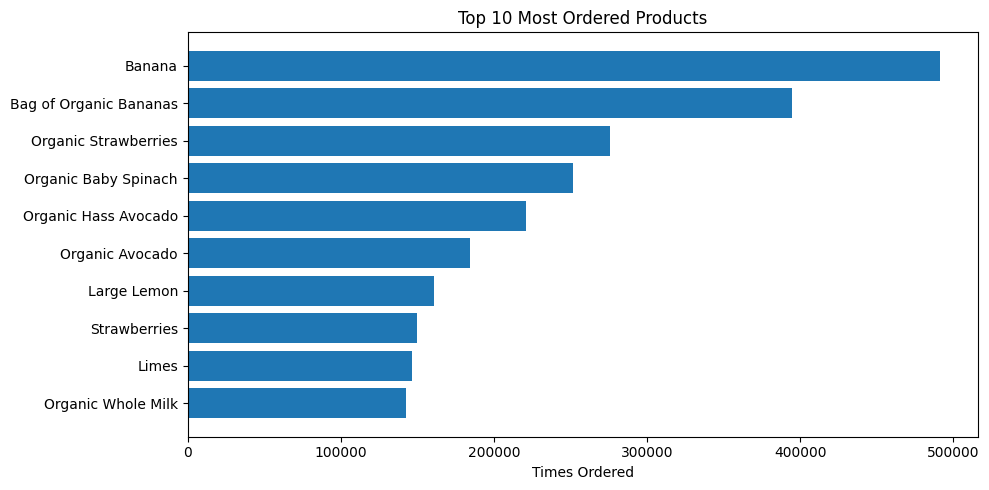

In [15]:
# Top 10 Products
import matplotlib.pyplot as plt

top10 = duckdb.sql("""
select p.product_name,
       count(*) as times_ordered
from '../data/all_order_products.csv' op
join '../data/products.csv' p
  on op.product_id = p.product_id
group by p.product_name
order by times_ordered desc
limit 10
""").df()

plt.figure(figsize=(10, 5))
plt.barh(top10["product_name"], top10["times_ordered"])
plt.gca().invert_yaxis()
plt.title("Top 10 Most Ordered Products")
plt.xlabel("Times Ordered")
plt.tight_layout()
plt.show()

In [16]:
plt.savefig("../top10_products.png", dpi = 150)

<Figure size 640x480 with 0 Axes>

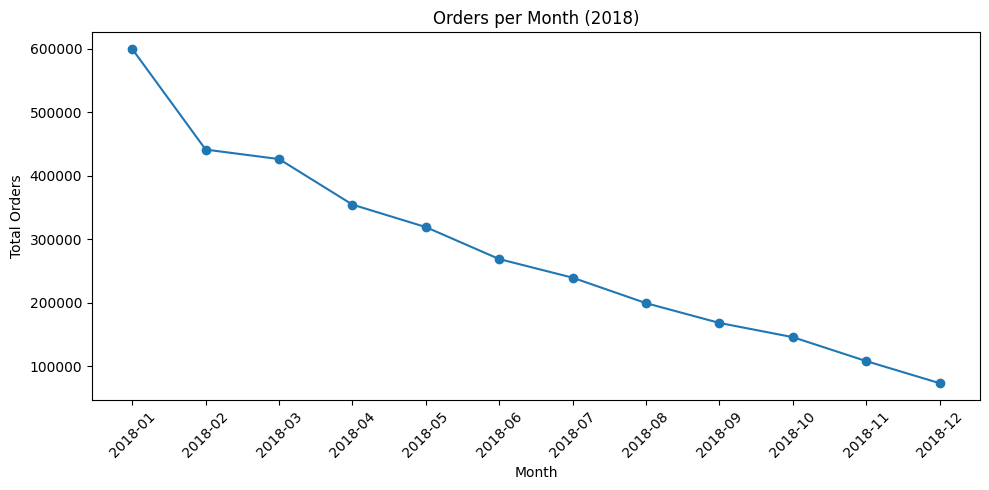

In [17]:
# orders per month
# Chart 2: Monthly orders
monthly = duckdb.sql("""
select strftime(timestamp, '%Y-%m') as month,
       count(*) as total_orders
from '../data/orders.csv'
where timestamp < '2019-01-01'
group by month
order by month
""").df()

plt.figure(figsize=(10, 5))
plt.plot(monthly["month"], monthly["total_orders"], marker="o")
plt.title("Orders per Month (2018)")
plt.xlabel("Month")
plt.ylabel("Total Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../monthly_orders.png", dpi=150)
plt.show()

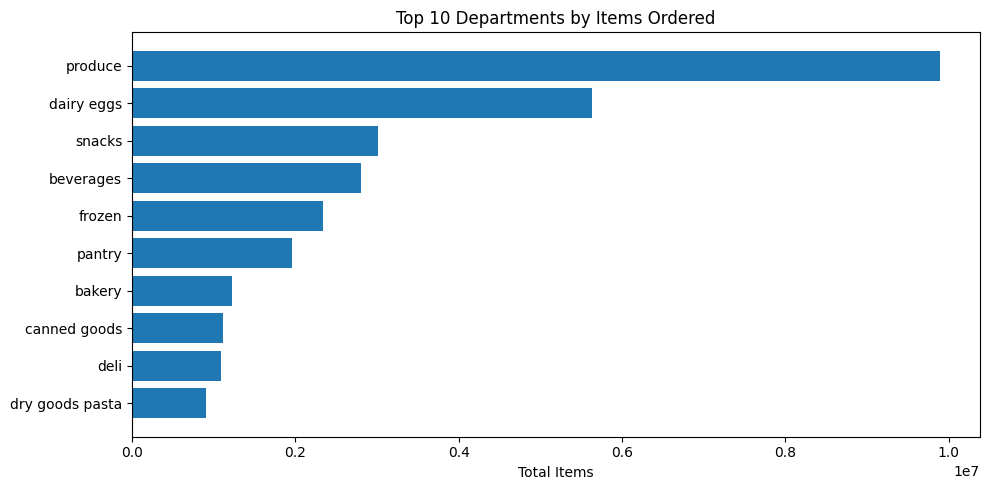

In [18]:
# Chart 3: Department sales
dept_names = {
    1: "frozen", 2: "other", 3: "bakery", 4: "produce", 5: "alcohol",
    6: "international", 7: "beverages", 8: "pets", 9: "dry goods pasta",
    10: "bulk", 11: "personal care", 12: "meat seafood", 13: "pantry",
    14: "breakfast", 15: "canned goods", 16: "dairy eggs", 17: "household",
    18: "babies", 19: "snacks", 20: "deli", 21: "missing"
}

dept = duckdb.sql("""
select p.department_id,
       count(*) as total_items
from '../data/all_order_products.csv' op
join '../data/products.csv' p
  on op.product_id = p.product_id
group by p.department_id
order by total_items desc
""").df()

dept["department_name"] = dept["department_id"].map(dept_names)
top = dept.head(10)

plt.figure(figsize=(10, 5))
plt.barh(top["department_name"], top["total_items"])
plt.gca().invert_yaxis()
plt.title("Top 10 Departments by Items Ordered")
plt.xlabel("Total Items")
plt.tight_layout()
plt.savefig("../department_sales.png", dpi=150)
plt.show()